In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from torch.utils.data import TensorDataset, DataLoader, random_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

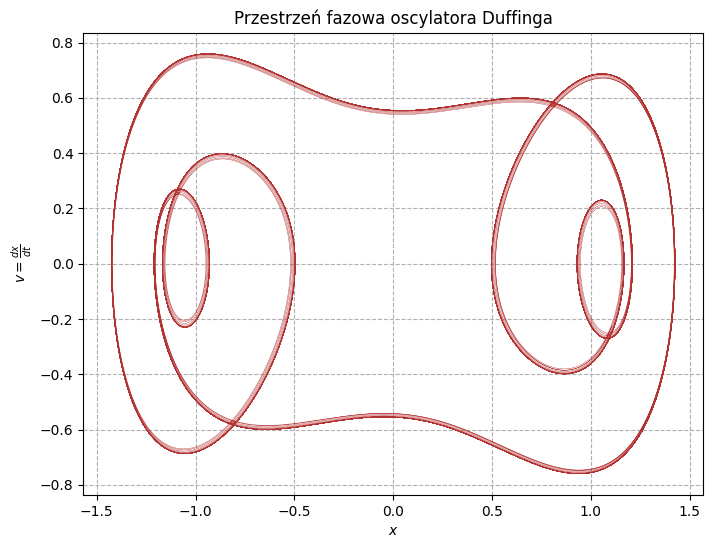

In [ ]:
#PHASE DIAGRAM VISUALIZATION

DELTA = 0.2
ALFA = -1.0
BETA = 1.0
GAMMA = 0.3
OMEGA = 1.2

def duffing(t, z):
    x, v = z
    dxdt = v
    dvdt = -DELTA*v - ALFA*x - BETA*x**3 + GAMMA*np.cos(OMEGA*t)
    return [dxdt, dvdt]

t_final = 1000  
t_eval = np.linspace(0, t_final, 100000)

x0 = 0.1
v0 = 0.0
z0 = [x0, v0]

sol = solve_ivp(duffing, [0, t_final], z0, t_eval=t_eval, rtol=1e-8, atol=1e-8)

x_val = sol.y[0]
v_val = sol.y[1]

cut = int(0.4 * len(x_val))

plt.figure(figsize=(8, 6))
plt.plot(x_val[cut:], v_val[cut:], color=(0.7, 0.2, 0.2), linewidth=0.3)
plt.xlabel("$x$")
plt.ylabel(r"$v = \frac{dx}{dt}$")
plt.title("Przestrzeń fazowa oscylatora Duffinga")
plt.grid(ls='--')
plt.show()

In [ ]:
#GLOBAL

NUM_SAMPLES = 5000
NUM_TIME_STEPS = 100
T_MAX = 20.0
t_eval = np.linspace(0, T_MAX, NUM_TIME_STEPS)

In [ ]:
#GROUND TRUTH

def duffing_deriv(t, state, alpha, beta, delta, gamma, omega):
    x, v = state
    dxdt = v
    dvdt = gamma * np.cos(omega * t) - delta * v - alpha * x - beta * (x**3)
    return [dxdt, dvdt]

In [ ]:
#DATASET GENERATION

def generate_data(num_samples):
    X_data = np.zeros((num_samples, 7))
    Y_data = np.zeros((num_samples, NUM_TIME_STEPS))
    
    for i in range(num_samples):
        alpha = np.random.uniform(-1.0, 1.0)
        beta = np.random.uniform(0.1, 1.0)
        delta = np.random.uniform(0.0, 0.5)
        gamma = np.random.uniform(0.0, 1.0)
        omega = np.random.uniform(0.5, 1.5)
        x0 = np.random.uniform(-2.0, 2.0)
        v0 = np.random.uniform(-2.0, 2.0)
        
        params = (alpha, beta, delta, gamma, omega)
        sol = solve_ivp(duffing_deriv, [0, T_MAX], [x0, v0], args=params, t_eval=t_eval)
        
        X_data[i] = [alpha, beta, delta, gamma, omega, x0, v0]
        Y_data[i] = sol.y[0]
        
    return torch.tensor(X_data, dtype=torch.float32), torch.tensor(Y_data, dtype=torch.float32)


In [ ]:
#NEURAL NETWORK

class DuffingNet(nn.Module):
    def __init__(self, input_dim=7, output_dim=100):
        super(DuffingNet, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.GELU(),
            nn.Linear(64, 128),
            nn.GELU(),
            nn.Linear(128, 128),
            nn.GELU(),
            nn.Linear(128, output_dim)
        )

    def forward(self, x):
        return self.net(x)

In [ ]:
#HYBRID LOSS

from scipy.interpolate import CubicSpline

XI = 0.65


T = len(t_eval)
cs = CubicSpline(t_eval, np.eye(T), bc_type='not-a-knot', axis=0)

t_col = np.linspace(0, T_MAX, 2 * T - 1)[1:-1]

D0 = torch.tensor(cs(t_col, 0), dtype=torch.float32, device=device)
D1 = torch.tensor(cs(t_col, 1), dtype=torch.float32, device=device)
D2 = torch.tensor(cs(t_col, 2), dtype=torch.float32, device=device)
t_col_t = torch.tensor(t_col, dtype=torch.float32, device=device).unsqueeze(0)

PHYS_SCALE = 1.0 #adjust if losses are orders of magnitude differenr

def physics_loss_fn(x_pred, params):
    alpha, beta, delta, gamma, omega = [params[:, i:i+1] for i in range(5)]

    x    = x_pred @ D0.T
    x_d  = x_pred @ D1.T
    x_dd = x_pred @ D2.T

    residual = x_dd + delta * x_d + alpha * x + beta * x**3 \
               - gamma * torch.cos(omega * t_col_t)
    return torch.mean(residual**2) / PHYS_SCALE

def compute_loss(model, batch_x, batch_y, xi=XI):
    pred = model(batch_x)
    truth_loss   = criterion(pred, batch_y)
    physics_loss = physics_loss_fn(pred, batch_x)
    total_loss   = xi * physics_loss + (1 - xi) * truth_loss
    return total_loss, truth_loss, physics_loss

In [ ]:
X, Y = generate_data(NUM_SAMPLES)
dataset = TensorDataset(X, Y)

train_size = 4000
test_size = 1000
train_dataset, test_dataset = random_split(dataset, [train_size, test_size])

pin = device.type == "cuda"
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, pin_memory=pin)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, pin_memory=pin)

model = DuffingNet().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 500
for epoch in range(epochs):
    model.train()
    train_loss = train_truth = train_phys = 0.0
    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device, non_blocking=True)
        batch_y = batch_y.to(device, non_blocking=True)
        optimizer.zero_grad()
        loss, t_l, p_l = compute_loss(model, batch_x, batch_y)
        loss.backward()
        optimizer.step()
        train_loss  += loss.item()
        train_truth += t_l.item()
        train_phys  += p_l.item()

    model.eval()
    test_loss = test_truth = test_phys = 0.0
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x = batch_x.to(device, non_blocking=True)
            batch_y = batch_y.to(device, non_blocking=True)
            loss, t_l, p_l = compute_loss(model, batch_x, batch_y)
            test_loss  += loss.item()
            test_truth += t_l.item()
            test_phys  += p_l.item()

    if (epoch + 1) % 10 == 0:
        n_tr, n_te = len(train_loader), len(test_loader)
        print(f"Epoch {epoch+1}/{epochs} | "
              f"Train total: {train_loss/n_tr:.4f} (truth {train_truth/n_tr:.4f}, phys {train_phys/n_tr:.4f}) | "
              f"Test total: {test_loss/n_te:.4f} (truth {test_truth/n_te:.4f}, phys {test_phys/n_te:.4f})")

In [ ]:
def plot_phase_space(model, sample_params, t_eval):
    model.eval()
    with torch.no_grad():
        
        x_pred = model(sample_params.to(device)).cpu().numpy().flatten()
    
    dt = t_eval[1] - t_eval[0]
    
    v_pred = np.gradient(x_pred, dt)
    
    plt.figure(figsize=(8, 6))
    plt.plot(x_pred, v_pred, label="Predykcja sieci", color='blue')
    plt.title("Przestrzeń fazowa oscylatora Duffinga")
    plt.xlabel(r"$ x(t)$")
    plt.ylabel(r"$ v(t) = \frac{dx}{dt}$")
    plt.grid(True)
    plt.legend()
    plt.show()

sample_idx = 0
sample_x, sample_y = test_dataset[sample_idx]
plot_phase_space(model, sample_x.unsqueeze(0), t_eval)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_attractor_with_vector_field(model, sample_params, t_eval):
    model.eval()
    
    params = sample_params.cpu().numpy().flatten()
    alpha, beta, delta, gamma, omega, _, _ = params

    with torch.no_grad():
        x_pred = model(sample_params.to(device)).cpu().numpy().flatten()
    
    dt = t_eval[1] - t_eval[0]
    v_pred = np.gradient(x_pred, dt)
    
    fig, ax = plt.subplots(figsize=(10, 8))
    
    x_min, x_max = x_pred.min() - 0.5, x_pred.max() + 0.5
    v_min, v_max = v_pred.min() - 0.5, v_pred.max() + 0.5
    
    X_grid, V_grid = np.meshgrid(np.linspace(x_min, x_max, 20), 
                                 np.linspace(v_min, v_max, 20))
    
    t_snapshot = 0 
    U = V_grid
    V = gamma * np.cos(omega * t_snapshot) - delta * V_grid - alpha * X_grid - beta * (X_grid**3)
    
    ax.quiver(X_grid, V_grid, U, V, color='blue', alpha=0.3, angles='xy', scale_units='xy')
    
    ax.scatter(x_pred, v_pred, s=0.5, color='midnightblue', alpha=0.6, label='Punkty trajektorii')
    
    ax.set_title("Przestrzeń fazowa oscylatora Duffinga z polem wektorowym")
    ax.set_xlabel("Położenie x(t)")
    ax.set_ylabel("Prędkość v(t) = dx/dt")
    ax.grid(False)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    plt.show()


plot_attractor_with_vector_field(model, sample_x.unsqueeze(0), t_eval)